# Reproducible analysis of within-stem radial growth asymmetry

This notebook contains the analysis code available for the manuscript **No Universal South-Facing Growth Advantage in Northern Hemisphere Trees**. It calculates directional TGAI and absolute TGAI, summarizes site-level spatial and temporal patterns, extracts climate and mountain classifications, and produces the corresponding figures and tables.

Run the notebook from the project root after arranging the public input data as described in `README.md`. All paths are relative and all generated files are written to `outputs/figures` or `outputs/tables`.


In [1]:
from pathlib import Path
import os

PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "data"
TREE_RING_DIR = DATA_DIR / "tree_ring_width"
SITE_METADATA = DATA_DIR / "site_metadata" / "ITRDB.shp"
MOUNTAIN_MASK = DATA_DIR / "mountains" / "GMBA_2021_MntnMask_EarthEnv_30s1Bit.tif"
WORLD_BOUNDARIES = DATA_DIR / "boundaries" / "naturalearth_lowres.shp"
CRU_PRE = DATA_DIR / "climate" / "cru_ts4.07.1901.2022.pre.dat.nc"
CRU_TMP = DATA_DIR / "climate" / "cru_ts4.07.1901.2022.tmp.dat.nc"

OUTPUT_DIR = PROJECT_DIR / "outputs"
FIGURE_DIR = OUTPUT_DIR / "figures"
TABLE_DIR = OUTPUT_DIR / "tables"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_SEED = 42
START_YEAR = 1901
END_YEAR = 2000
MIN_OVERLAP_YEARS = 15
MIN_VALID_PAIRS = 4
SIGNIFICANCE_LEVEL = 0.05
ARIDITY_THRESHOLD = 0.65


## 1. Calculate pair-level TGAI and temporal trends


In [2]:
import os
import pandas as pd
import numpy as np
from scipy.stats import ttest_rel
from sklearn.linear_model import LinearRegression
import statsmodels.api as sm
folder = TREE_RING_DIR
results = []
for filename in os.listdir(folder):
    if not filename.lower().endswith(".rwl.csv"):
        continue
    filepath = os.path.join(folder, filename)
    try:
        df = pd.read_csv(filepath, index_col=0)
        df.index = df.index.astype(int)
        df = df[
            (df.index >= START_YEAR) &
            (df.index <= END_YEAR)
        ]
        df.columns = [
            str(col).upper()
            for col in df.columns
        ]
        all_cols = df.columns.tolist()
        # ====================================================
        # Find all N/S pairs.
        # ====================================================
        for col_n in [
            c for c in all_cols
            if c.endswith("N")
        ]:
            prefix = col_n[:-1]
            col_s = prefix + "S"

            if col_s not in all_cols:
                continue
            vals_n = df[col_n].dropna()
            vals_s = df[col_s].dropna()
            common_years = (
                vals_n.index
                .intersection(vals_s.index)
            )
            if len(common_years) < MIN_OVERLAP_YEARS:
                continue
            vals_n = vals_n.loc[common_years]
            vals_s = vals_s.loc[common_years]
            valid_mask = (
                (vals_n > 0) &
                (vals_s > 0)
            )
            vals_n = vals_n.loc[valid_mask]
            vals_s = vals_s.loc[valid_mask]

            if len(vals_n) < MIN_OVERLAP_YEARS:
                continue
            tgai = np.log(
                vals_s / vals_n
            )
            # =================================================
            # |TGAI|
            # =================================================
            abs_tgai = np.abs(tgai)
            t_stat, p_val_t = ttest_rel(
                vals_s,
                vals_n
            )
            x = tgai.index.values.reshape(-1, 1)
            y = tgai.values
            model = LinearRegression().fit(
                x,
                y
            )
            tgai_slope = model.coef_[0]
            tgai_r2 = model.score(x, y)
            x_sm = sm.add_constant(x)

            model_sm = sm.OLS(
                y,
                x_sm
            ).fit()
            tgai_p = model_sm.pvalues[1]
            y_abs = abs_tgai.values
            model_abs = LinearRegression().fit(
                x,
                y_abs
            )
            abs_tgai_slope = (
                model_abs.coef_[0]
            )
            abs_tgai_r2 = (
                model_abs.score(
                    x,
                    y_abs
                )
            )
            model_abs_sm = sm.OLS(
                y_abs,
                x_sm
            ).fit()
            abs_tgai_p = (
                model_abs_sm.pvalues[1]
            )
            results.append({
                'Filename': filename,
                'site': filename.replace(
                    '.rwl.csv',
                    ''
                ).upper(),
                'Prefix': prefix,
                'N_column': col_n,
                'S_column': col_s,
                'Start_year': tgai.index.min(),
                'End_year': tgai.index.max(),
                'N_years': len(tgai),
                'p_val_ttest': p_val_t,
                'std_N': vals_n.std(),
                'std_S': vals_s.std(),
                'Mean_TGAI':
                    tgai.mean(),
                'TGAI_Slope':
                    tgai_slope,
                'TGAI_p_val_slope':
                    tgai_p,
                'TGAI_R2':
                    tgai_r2,
                'Mean_abs_TGAI':
                    abs_tgai.mean(),
                'Abs_TGAI_Slope':
                    abs_tgai_slope,
                'Abs_TGAI_p_val_slope':
                    abs_tgai_p,
                'Abs_TGAI_R2':
                    abs_tgai_r2,
            })
    except Exception as e:

        print(
            f"Error processing {filename}: {e}"
        )
result_df = pd.DataFrame(results)
mean_val = result_df['Mean_TGAI'].mean()
std_val = result_df['Mean_TGAI'].std()
lower = mean_val - 3 * std_val
upper = mean_val + 3 * std_val
df_filtered = result_df[(result_df['Mean_TGAI'] >= lower) & (result_df['Mean_TGAI'] <= upper)]


## 2. Within-tree significance test (Figure S2)


p < 0.05: 77.5%


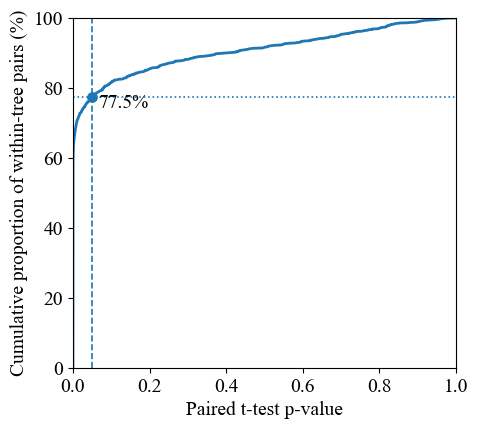

In [3]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['font.size'] = 14
plt.rcParams["xtick.labelsize"] = 14
plt.rcParams["ytick.labelsize"] = 14
pvals = (df_filtered['p_val_ttest'].dropna().values)
pvals_sorted = np.sort(pvals)
cum_prop = (np.arange(1, len(pvals_sorted) + 1)/ len(pvals_sorted) * 100)
pct_sig = np.mean(pvals < 0.05) * 100
print(f'p < 0.05: {pct_sig:.1f}%')
fig, ax = plt.subplots(figsize=(5, 4.5))
ax.plot(pvals_sorted, cum_prop, lw=2)
ax.axvline(0.05, linestyle='--', lw=1.2)
ax.axhline(pct_sig, linestyle=':', lw=1.2 )
ax.scatter(0.05, pct_sig, s=45, zorder=5)
ax.text(0.065, pct_sig - 3, f'{pct_sig:.1f}%', fontsize=14)
ax.set_xlabel('Paired t-test p-value')
ax.set_ylabel('Cumulative proportion of within-tree pairs (%)')
ax.set_xlim(0, 1)
ax.set_ylim(0, 100)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "Figure_S2_pvalue_cumulative_distribution.jpg", dpi=600, bbox_inches="tight")
plt.show()

## 3. Aggregate valid core pairs to sites


In [4]:
sig_df = df_filtered[(df_filtered['p_val_ttest'] < SIGNIFICANCE_LEVEL)]
grouped_summary_4 = (sig_df.groupby('Filename').filter(lambda df: len(df) >= MIN_VALID_PAIRS).groupby('Filename')  
    .agg(
        Slope_P=('Abs_TGAI_Slope', lambda x: (x > 0).mean()), 
        Mean=('Mean_TGAI', 'mean'),
        Slope_Mean=('TGAI_Slope', 'mean'), 
        Mean_abs_TGAI=('Mean_abs_TGAI', 'mean'),
        Slope_Mean_abs_TGAI=('Abs_TGAI_Slope', 'mean')            
    ).reset_index()  
)

In [5]:
import geopandas as gpd
df_siteg = gpd.read_file(SITE_METADATA)
grouped_summary_4["Site_ID"] = grouped_summary_4["Filename"].str.replace(r"\.rwl\.csv$", "", regex=True)
dfslope_4 = pd.merge(grouped_summary_4.loc[:,'Slope_P':],df_siteg.loc[:,['Latitude', 'Longitude','Site_ID','ai_v3','Tree_Speci']])
dfslope_4_N_P = dfslope_4[(dfslope_4['Latitude']>0)]
dfslope_4_N_P = dfslope_4_N_P[(dfslope_4_N_P['ai_v3'] >0)]


d:\software\Anaconda3\envs\dataProcessing\lib\site-packages\geopandas\_compat.py:124: UserWarning: The Shapely GEOS version (3.11.4-CAPI-1.17.4) is incompatible with the GEOS version PyGEOS was compiled with (3.10.4-CAPI-1.16.2). Conversions between both will be slow.
  warnings.warn(
C:\Users\MSI\AppData\Local\Temp\ipykernel_34836\869361376.py:1: DeprecationWarning: Shapely 2.0 is installed, but because PyGEOS is also installed, GeoPandas still uses PyGEOS by default. However, starting with version 0.14, the default will switch to Shapely. To force to use Shapely 2.0 now, you can either uninstall PyGEOS or set the environment variable USE_PYGEOS=0. You can do this before starting the Python process, or in your code before importing geopandas:

import os
os.environ['USE_PYGEOS'] = '0'
import geopandas

In the next release, GeoPandas will switch to using Shapely by default, even if PyGEOS is installed. If you only have PyGEOS installed to get speed-ups, this switch should be smooth. How

In [6]:
mean_num = (dfslope_4_N_P.groupby(["Latitude", "Longitude"], as_index=False).mean(numeric_only=True))
meta = (dfslope_4_N_P.sort_values(["Latitude", "Longitude"]).groupby(["Latitude", "Longitude"], as_index=False).first()  
    [["Latitude", "Longitude", "Tree_Speci", "Site_ID"]]
)
dfslope_4_N_P_mean = mean_num.merge(meta, on=["Latitude", "Longitude"], how="left")

## 4. Add chronology statistics and export site summaries


In [7]:
import pandas as pd
from pathlib import Path
stats_dir = TREE_RING_DIR
rows = []
for f in stats_dir.glob("*.rwl.stats.csv"):
    s = pd.read_csv(f)
    rows.append({
        "Site_ID": f.name.replace(".rwl.stats.csv", ""),
        "eps": s["eps"].iloc[0],
        "snr": s["snr"].iloc[0],
    })
stats_all = pd.DataFrame(rows)
dfslope_4_N_P_mean["Site_ID"] = dfslope_4_N_P_mean["Site_ID"].astype(str)
stats_all["Site_ID"] = stats_all["Site_ID"].astype(str)

dfslope_4_N_P_mean = dfslope_4_N_P_mean.drop(columns=["eps", "snr"], errors="ignore").merge(
    stats_all, on="Site_ID", how="left"
)


In [8]:
dfslope_4_N_P_mean.to_csv(TABLE_DIR / "site_level_TGAI.csv", index=False)

## 5. Spatial pattern of directional TGAI (Figure 1a)


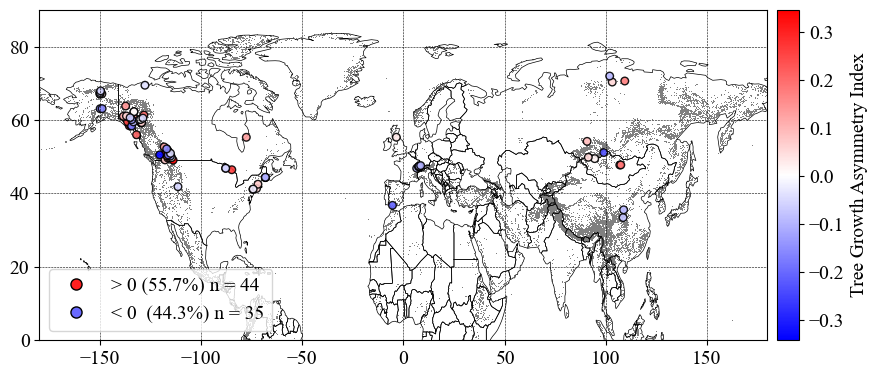

In [9]:
import matplotlib.pyplot as plt
from shapely.geometry import Point
import matplotlib.colors as mcolors
import matplotlib.cm as cm
from mpl_toolkits.axes_grid1 import make_axes_locatable
import geopandas as gpd
import numpy as np
from matplotlib.lines import Line2D
import rasterio
from rasterio.plot import show
from matplotlib.colors import ListedColormap
# Plot settings
plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['font.size'] = 14
plt.rcParams["xtick.labelsize"] = 14
plt.rcParams["ytick.labelsize"] = 14
# Read the K3 mountain mask
tif_path = MOUNTAIN_MASK
with rasterio.open(tif_path) as src:
    mountain_mask = src.read(1)
    transform = src.transform
    bounds = src.bounds
extent = [bounds.left, bounds.right, bounds.bottom, bounds.top]
mountain_cmap = ListedColormap(['white', 'gray'])
geometry = [Point(xy) for xy in zip(dfslope_4_N_P_mean['Longitude'], dfslope_4_N_P_mean['Latitude'])]
gdf = gpd.GeoDataFrame(dfslope_4_N_P_mean, geometry=geometry, crs='EPSG:4326')
conditions = [
    gdf['Mean'] > 0,
    gdf['Mean'] < 0,
    gdf['Mean'] == 0
]
choices = ['> 0', '< 0', '= 0']
gdf['mean_class'] = np.select(conditions, choices, default='= 0')
gdf_gt = gdf[gdf['mean_class'] == '> 0']
gdf_lt = gdf[gdf['mean_class'] == '< 0']
gdf_eq = gdf[gdf['mean_class'] == '= 0']
total = len(gdf)
p_gt = f"({len(gdf_gt)/total*100:.1f}%) n = {len(gdf_gt)} "
p_lt = f" ({len(gdf_lt)/total*100:.1f}%) n = {len(gdf_lt)}"
p_eq = f"({len(gdf_eq)/total*100:.1f}%) n = {len(gdf_eq)}"
world = gpd.read_file(WORLD_BOUNDARIES)
vmin = gdf['Mean'].min()
vcenter = 0
vmax = gdf['Mean'].max()
norm = mcolors.TwoSlopeNorm(vmin=vmin, vcenter=vcenter, vmax=vmax)
cmap = cm.bwr
fig, ax = plt.subplots(figsize=(9, 4))
ax.imshow(mountain_mask, cmap=mountain_cmap, extent=extent, interpolation='none')
world.plot(ax=ax, color='none', edgecolor='black', linewidth=0.5)
divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="3%", pad=0.1)
if not gdf_eq.empty:
    gdf_eq.plot(
        ax=ax,
        facecolor='white',
        edgecolor='gray',
        linewidth=1.2,
        markersize=20,
        label='= 1 ' + p_eq
    )

if not gdf_gt.empty:
    gdf_gt.plot(
        ax=ax,
        column='Mean',
        cmap=cmap,
        norm=norm,
        markersize=30,
        edgecolor='k',
        alpha=0.9
    )

if not gdf_lt.empty:
    gdf_lt.plot(
        ax=ax,
        column='Mean',
        cmap=cmap,
        norm=norm,
        markersize=30,
        edgecolor='k',
        alpha=0.9
    )
sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cb = plt.colorbar(sm, cax=cax)
cb.set_label("Tree Growth Asymmetry Index")
legend_elements = [
    Line2D([0], [0], marker='o', color='w', label=f'> 0 {p_gt}',
           markerfacecolor=cmap(norm(0.3)), markeredgecolor='k', markersize=8),
    # Line2D([0], [0], marker='o', color='w', label=f'= 0 {p_eq}',
    #        markerfacecolor='white', markeredgecolor='gray', markersize=8),
    Line2D([0], [0], marker='o', color='w', label=f'< 0 {p_lt}',
           markerfacecolor=cmap(norm(-0.2)), markeredgecolor='k', markersize=8),
]
ax.legend(handles=legend_elements, loc='lower left', fontsize=14, frameon=True)
ax.set_xlim(-180, 180)
ax.set_ylim(0, 90)

ax.set_aspect('auto')
ax.grid(True, linestyle='--', color='black', linewidth=0.4)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "Figure_1a_spatial_TGAI.jpg", dpi=600, bbox_inches="tight")
plt.show()


## 6. Compare asymmetry magnitude by dominant direction (Figure S3)


South > North, n = 44
South < North, n = 35
P = 0.5116


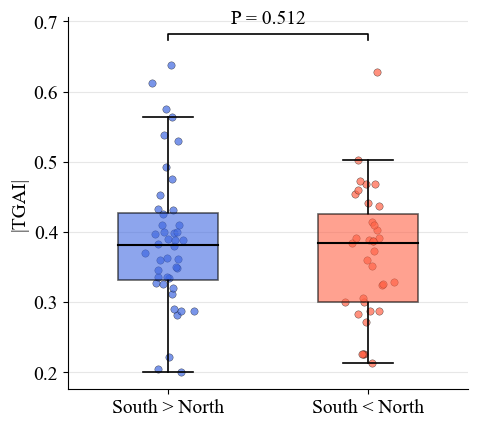

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu
dfcs = dfslope_4_N_P_mean.copy()
dfcs = dfcs.dropna(subset=['Mean', 'Mean_abs_TGAI'])
group_pos = dfcs.loc[dfcs['Mean'] > 0, 'Mean_abs_TGAI'].dropna()
group_neg = dfcs.loc[dfcs['Mean'] < 0, 'Mean_abs_TGAI'].dropna()
stat, p = mannwhitneyu(group_pos, group_neg, alternative='two-sided')
print(f"South > North, n = {len(group_pos)}")
print(f"South < North, n = {len(group_neg)}")
print(f"P = {p:.4f}")
fig, ax = plt.subplots(figsize=(5, 4.5))
data_to_plot = [group_pos.values, group_neg.values]
colors = ['royalblue', 'tomato']

bp = ax.boxplot(
    data_to_plot,
    patch_artist=True,
    widths=0.5,
    showfliers=False,
    medianprops=dict(color='black', linewidth=1.5),
    whiskerprops=dict(color='black', linewidth=1.2),
    capprops=dict(color='black', linewidth=1.2),
    boxprops=dict(edgecolor='black', linewidth=1.2)
)

for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.6)
for i, (group, color) in enumerate(zip(data_to_plot, colors), start=1):
    x = np.random.default_rng(RANDOM_SEED).normal(i, 0.06, size=len(group))
    ax.scatter(x, group, alpha=0.7, s=28, color=color, edgecolor='black', linewidth=0.3)
ax.set_xticks([1, 2])
ax.set_xticklabels(['South > North', 'South < North'])
ax.set_ylabel('|TGAI|')
y_max = max(np.max(group_pos), np.max(group_neg))
y_min = min(np.min(group_pos), np.min(group_neg))
y_range = y_max - y_min
line_y = y_max + 0.08 * y_range
text_y = y_max + 0.12 * y_range
ax.plot(
    [1, 1, 2, 2],
    [line_y, line_y + 0.02*y_range, line_y + 0.02*y_range, line_y],
    lw=1.2, c='black'
)

if p < 0.001:
    p_text = 'P < 0.001'
else:
    p_text = f'P = {p:.3f}'
ax.text(1.5, text_y, p_text, ha='center', va='bottom', fontsize=14)
ax.grid(axis='y', alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "Figure_S3_directional_group_comparison.jpg", dpi=600, bbox_inches="tight")
plt.show()


## 7. Mountain classification and comparison (Figure S11)


In [11]:
import numpy as np
import rasterio
from pyproj import Transformer
tif_path = MOUNTAIN_MASK
with rasterio.open(tif_path) as src:
    valid = dfcs["Longitude"].notna() & dfcs["Latitude"].notna()
    lon = dfcs.loc[valid, "Longitude"].values
    lat = dfcs.loc[valid, "Latitude"].values

    if src.crs is not None and src.crs.to_epsg() != 4326:
        transformer = Transformer.from_crs("EPSG:4326", src.crs, always_xy=True)
        x, y = transformer.transform(lon, lat)
    else:
        x, y = lon, lat
    values = np.array([v[0] for v in src.sample(list(zip(x, y)))])
dfcs["Is_Mountain"] = np.nan
dfcs.loc[valid, "Is_Mountain"] = values

C:\Users\MSI\AppData\Local\Temp\ipykernel_34836\200182472.py:17: DeprecationWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  dfcs.loc[valid, "Is_Mountain"] = values


C:\Users\MSI\AppData\Local\Temp\ipykernel_34836\1524189690.py:25: DeprecationWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  dfcs.loc[valid_coord, "Is_Mountain"] = (values == 1).astype(int)
C:\Users\MSI\AppData\Local\Temp\ipykernel_34836\1524189690.py:119: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax2.set_xticklabels([f"{abs(t):.0f}" for t in ticks])


    Latitude   Longitude  Is_Mountain
0  33.440325  108.654847            1
1  35.554255  108.905503            0
2  36.768000   -5.415830            1
3  41.115000  -74.420000            0
4  41.206000  -74.326000            0
Mountain,     n = 45
Non-mountain, n = 34
U = 753.5000, P = 0.9133


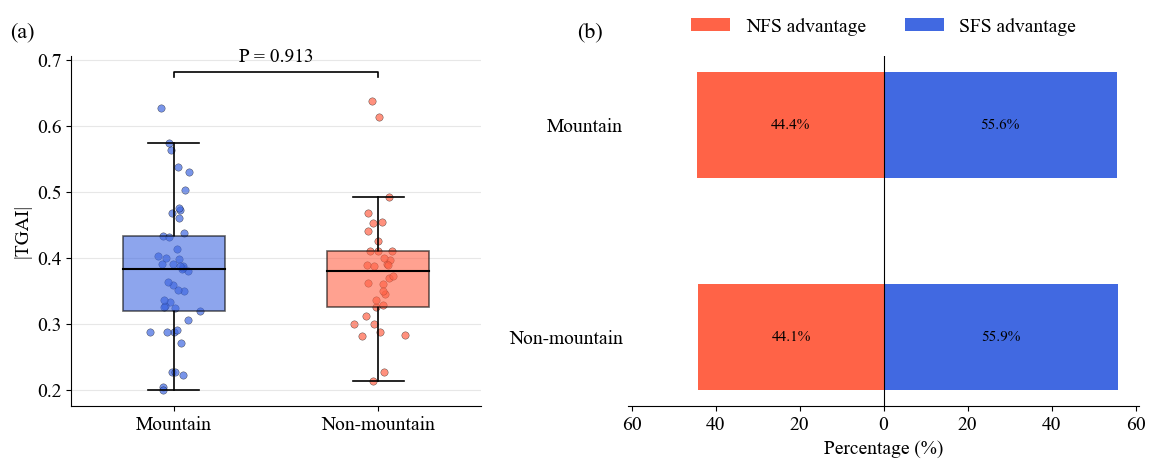

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu
import rasterio
from pyproj import Transformer
# =========================================================
# Sample the K3 mountain mask at each site
# =========================================================
tif_path = MOUNTAIN_MASK
with rasterio.open(tif_path) as src:
    valid_coord = dfcs["Longitude"].notna() & dfcs["Latitude"].notna()
    lon = dfcs.loc[valid_coord, "Longitude"].values
    lat = dfcs.loc[valid_coord, "Latitude"].values

    if src.crs is not None and src.crs.to_epsg() != 4326:
        transformer = Transformer.from_crs("EPSG:4326", src.crs, always_xy=True)
        x, y = transformer.transform(lon, lat)
    else:
        x, y = lon, lat

    values = np.array([v[0] for v in src.sample(zip(x, y))])

dfcs["Is_Mountain"] = np.nan
dfcs.loc[valid_coord, "Is_Mountain"] = (values == 1).astype(int)
print(dfcs[["Latitude", "Longitude", "Is_Mountain"]].head())
# =========================================================
# Compare absolute TGAI between mountain classes
# =========================================================
dfcs_m = dfcs.dropna(subset=["Is_Mountain", "Mean_abs_TGAI"]).copy()
dfcs_m["Is_Mountain"] = dfcs_m["Is_Mountain"].astype(int)
group_mtn  = dfcs_m.loc[dfcs_m["Is_Mountain"] == 1, "Mean_abs_TGAI"].dropna()
group_flat = dfcs_m.loc[dfcs_m["Is_Mountain"] == 0, "Mean_abs_TGAI"].dropna()
stat, p = mannwhitneyu(group_mtn, group_flat, alternative="two-sided")
print(f"Mountain,     n = {len(group_mtn)}")
print(f"Non-mountain, n = {len(group_flat)}")
print(f"U = {stat:.4f}, P = {p:.4g}")
data_to_plot = [group_mtn.values, group_flat.values]
colors = ["royalblue", "tomato"]
# =========================================================
# Calculate directional proportions by mountain class
# =========================================================
valid_mean = dfcs["Mean"].notna() & dfcs["Is_Mountain"].notna() & (dfcs["Mean"] != 0)
count_table = pd.crosstab(
    dfcs.loc[valid_mean, "Is_Mountain"],
    np.where(dfcs.loc[valid_mean, "Mean"] > 0, "Mean > 0", "Mean < 0"),
)
percent_table = count_table.div(count_table.sum(axis=1), axis=0) * 100
plot_data = percent_table.reindex(columns=["Mean > 0", "Mean < 0"], fill_value=0)

labels = ["Non-mountain" if v == 0 else "Mountain" for v in plot_data.index]
pos = plot_data["Mean > 0"].values
neg = plot_data["Mean < 0"].values
# =========================================================
# Plot both comparisons
# =========================================================
fig, (ax1, ax2) = plt.subplots(
    1, 2, figsize=(12, 5.0),
    gridspec_kw={"width_ratios": [1, 1.25]}
)

# Absolute TGAI boxplot
bp = ax1.boxplot(
    data_to_plot,
    patch_artist=True,
    widths=0.5,
    showfliers=False,
    medianprops=dict(color="black", linewidth=1.5),
    whiskerprops=dict(color="black", linewidth=1.2),
    capprops=dict(color="black", linewidth=1.2),
    boxprops=dict(edgecolor="black", linewidth=1.2),
)
for patch, color in zip(bp["boxes"], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.6)
for i, (group, color) in enumerate(zip(data_to_plot, colors), start=1):
    xj = np.random.default_rng(RANDOM_SEED).normal(i, 0.06, size=len(group))
    ax1.scatter(xj, group, alpha=0.7, s=28, color=color,
                edgecolor="black", linewidth=0.3)
ax1.set_xticks([1, 2])
ax1.set_xticklabels(["Mountain", "Non-mountain"])
ax1.set_ylabel("|TGAI|")

y_max = max(np.max(group_mtn), np.max(group_flat))
y_min = min(np.min(group_mtn), np.min(group_flat))
y_range = y_max - y_min

line_y = y_max + 0.08 * y_range
text_y = y_max + 0.12 * y_range
ax1.plot([1, 1, 2, 2],
         [line_y, line_y + 0.02 * y_range, line_y + 0.02 * y_range, line_y],
         lw=1.2, c="black")

p_text = "P < 0.001" if p < 0.001 else f"P = {p:.3f}"
ax1.text(1.5, text_y, p_text, ha="center", va="bottom", fontsize=14)

ax1.grid(axis="y", alpha=0.3)
ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)

# Directional TGAI proportions
y = np.arange(len(labels))
ax2.barh(y, -neg, height=0.5, color="tomato",    label="NFS advantage")
ax2.barh(y,  pos, height=0.5, color="royalblue", label="SFS advantage")

for i in range(len(y)):
    ax2.text(-neg[i] / 2, y[i], f"{neg[i]:.1f}%",
             ha="center", va="center", fontsize=11)
    ax2.text( pos[i] / 2, y[i], f"{pos[i]:.1f}%",
             ha="center", va="center", fontsize=11)

ax2.axvline(0, color="black", lw=0.8)
ax2.set_yticks(y)
ax2.set_yticklabels(labels)

max_range = max(pos.max(), neg.max()) + 5
ax2.set_xlim(-max_range, max_range)
ticks = ax2.get_xticks()
ax2.set_xticklabels([f"{abs(t):.0f}" for t in ticks])
ax2.set_xlabel("Percentage (%)")

ax2.legend(frameon=False, loc="upper center",
           bbox_to_anchor=(0.5, 1.16), ncol=2)

ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)
ax2.spines["left"].set_visible(False)
ax2.tick_params(axis="y", length=0)

# Panel labels
ax1.text(-0.15, 1.04, "(a)", transform=ax1.transAxes,
         fontsize=16, va="bottom", ha="left")
ax2.text(-0.10, 1.04, "(b)", transform=ax2.transAxes,
         fontsize=16, va="bottom", ha="left")

# Layout
plt.subplots_adjust(left=0.08, right=0.97, bottom=0.12, top=0.82, wspace=0.32)

plt.savefig(FIGURE_DIR / "Figure_S11_mountain_comparison.jpg", dpi=600, bbox_inches="tight")
plt.show()


## 8. Spatial trends and within-site consistency (Figure 2a and Figure S5)


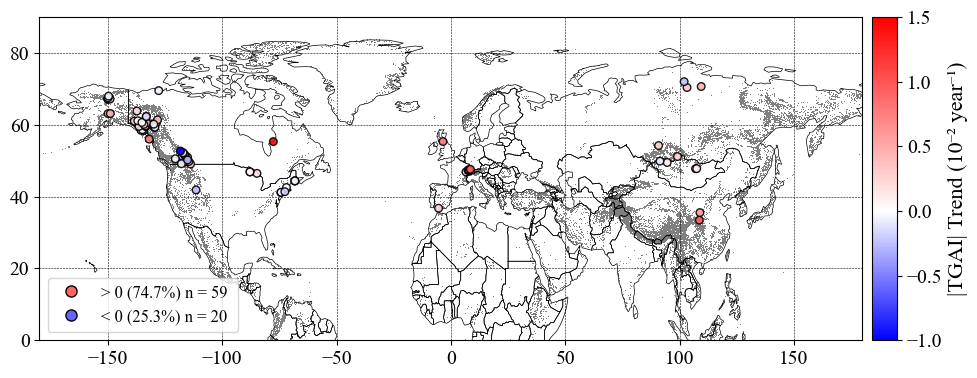

In [13]:
import matplotlib.pyplot as plt
from shapely.geometry import Point
import matplotlib.colors as mcolors
import matplotlib.cm as cm
from mpl_toolkits.axes_grid1 import make_axes_locatable
import geopandas as gpd
import numpy as np
from matplotlib.lines import Line2D
import rasterio
from rasterio.plot import show
from matplotlib.colors import ListedColormap
# Plot settings
plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['font.size'] = 14
plt.rcParams["xtick.labelsize"] = 14
plt.rcParams["ytick.labelsize"] = 14
tif_path = MOUNTAIN_MASK
with rasterio.open(tif_path) as src:
    mountain_mask = src.read(1)
    transform = src.transform
    bounds = src.bounds
    raster_crs = src.crs  

extent = [bounds.left, bounds.right, bounds.bottom, bounds.top]
mountain_cmap = ListedColormap(['white', 'gray'])
geometry = [Point(xy) for xy in zip(dfslope_4_N_P_mean['Longitude'], dfslope_4_N_P_mean['Latitude'])]
gdf = gpd.GeoDataFrame(dfslope_4_N_P_mean, geometry=geometry, crs='EPSG:4326')
if raster_crs != gdf.crs:
    gdf = gdf.to_crs(raster_crs)
conditions = [
    gdf['Slope_Mean_abs_TGAI'] > 0,
    gdf['Slope_Mean_abs_TGAI'] < 0
]
choices = ['> 0', '< 0']
gdf['mean_class'] = np.select(conditions, choices, default=np.nan)
gdf_gt = gdf[gdf['mean_class'] == '> 0']
gdf_lt = gdf[gdf['mean_class'] == '< 0']
total = len(gdf_gt) + len(gdf_lt)
p_gt = f"({len(gdf_gt)/total*100:.1f}%) n = {len(gdf_gt)} "
p_lt = f"({len(gdf_lt)/total*100:.1f}%) n = {len(gdf_lt)} "
world = gpd.read_file(WORLD_BOUNDARIES)
vmin = gdf['Slope_Mean_abs_TGAI'].min()
vcenter = 0
vmax = gdf['Slope_Mean_abs_TGAI'].max()
norm = mcolors.TwoSlopeNorm(vmin=vmin, vcenter=vcenter, vmax=vmax)
cmap = cm.bwr
fig, ax = plt.subplots(figsize=(10, 4))
ax.imshow(mountain_mask, cmap=mountain_cmap, extent=extent, interpolation='none', zorder=0)
world.to_crs(gdf.crs).plot(ax=ax, color='none', edgecolor='black', linewidth=0.5, zorder=1)
divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="3%", pad=0.1)
if not gdf_gt.empty:
    gdf_gt.plot(
        ax=ax, column='Slope_Mean_abs_TGAI', cmap=cmap, norm=norm,
        markersize=30, edgecolor='k', alpha=0.9, zorder=3
    )

if not gdf_lt.empty:
    gdf_lt.plot(
        ax=ax, column='Slope_Mean_abs_TGAI', cmap=cmap, norm=norm,
        markersize=30, edgecolor='k', alpha=0.9, zorder=3
    )
vmin = -1.0
vmax = 1.5
norm = mcolors.TwoSlopeNorm(vmin=vmin, vcenter=0, vmax=vmax)
cmap = cm.bwr
sm = cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
cb = plt.colorbar(sm, cax=cax)
cb.set_ticks([-1.0, -0.5, 0, 0.5, 1.0, 1.5])
cb.set_label("|TGAI| Trend (10⁻² year⁻¹)", fontsize=16)
cb.ax.tick_params(labelsize=14)
legend_elements = [
    Line2D([0], [0], marker='o', color='w', label=f'> 0 {p_gt}',
           markerfacecolor=cmap(norm(vmax*0.6)), markeredgecolor='k', markersize=8),
    Line2D([0], [0], marker='o', color='w', label=f'< 0 {p_lt}',
           markerfacecolor=cmap(norm(vmin*0.6)), markeredgecolor='k', markersize=8),
]
ax.legend(handles=legend_elements, loc='lower left', fontsize=12, frameon=True)
ax.set_xlim(-180, 180)
ax.set_ylim(0, 90)
ax.set_aspect('auto')
ax.grid(True, linestyle='--', color='black', linewidth=0.4)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "Figure_2a_spatial_TGAI_trends.jpg", dpi=600, bbox_inches="tight")
plt.show()

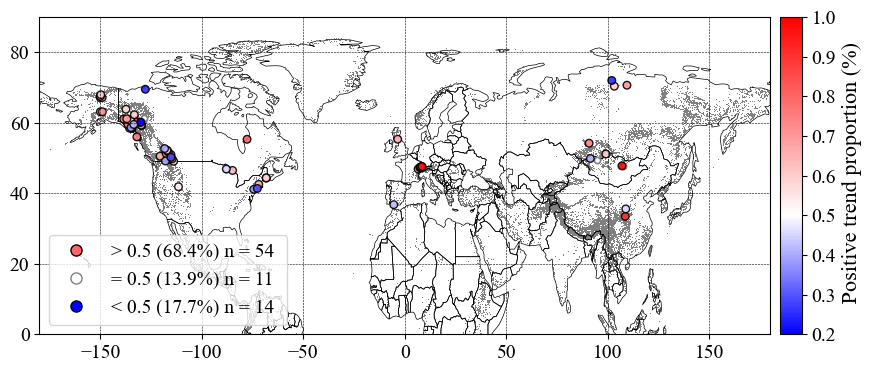

In [14]:
import matplotlib.pyplot as plt
from shapely.geometry import Point
import matplotlib.colors as mcolors
import matplotlib.cm as cm
from mpl_toolkits.axes_grid1 import make_axes_locatable
import geopandas as gpd
import numpy as np
from matplotlib.lines import Line2D
import rasterio
from rasterio.plot import show
from matplotlib.colors import ListedColormap
plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['font.size'] = 16
plt.rcParams["xtick.labelsize"] = 14
plt.rcParams["ytick.labelsize"] = 14
tif_path = MOUNTAIN_MASK

with rasterio.open(tif_path) as src:
    mountain_mask = src.read(1)
    transform = src.transform
    bounds = src.bounds
extent = [bounds.left, bounds.right, bounds.bottom, bounds.top]
mountain_cmap = ListedColormap(['white', 'gray'])
geometry = [Point(xy) for xy in zip(dfslope_4_N_P_mean['Longitude'], dfslope_4_N_P_mean['Latitude'])]
gdf = gpd.GeoDataFrame(dfslope_4_N_P_mean, geometry=geometry, crs='EPSG:4326')
conditions = [
    gdf['Slope_P'] > 0.5,
    gdf['Slope_P'] < 0.5,
    gdf['Slope_P'] == 0.5
]
choices = ['> 0.5', '< 0.5', '= 0.5']
gdf['mean_class'] = np.select(conditions, choices, default='= 0.5')

gdf_gt = gdf[gdf['mean_class'] == '> 0.5']
gdf_lt = gdf[gdf['mean_class'] == '< 0.5']
gdf_eq = gdf[gdf['mean_class'] == '= 0.5']
total = len(gdf)
p_gt = f"({len(gdf_gt)/total*100:.1f}%) n = {len(gdf_gt)} "
p_lt = f"({len(gdf_lt)/total*100:.1f}%) n = {len(gdf_lt)}"
p_eq = f"({len(gdf_eq)/total*100:.1f}%) n = {len(gdf_eq)}"
world = gpd.read_file(WORLD_BOUNDARIES)
vmin = gdf['Slope_P'].min()
vcenter = 0.5
vmax = gdf['Slope_P'].max()
norm = mcolors.TwoSlopeNorm(vmin=vmin, vcenter=vcenter, vmax=vmax)
cmap = cm.bwr
fig, ax = plt.subplots(figsize=(9, 4))
ax.imshow(mountain_mask, cmap=mountain_cmap, extent=extent, interpolation='none')
world.plot(ax=ax, color='none', edgecolor='black', linewidth=0.5)
divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="3%", pad=0.1)
if not gdf_eq.empty:
    gdf_eq.plot(
        ax=ax,
        facecolor='white',
        edgecolor='gray',
        linewidth=1.2,
        markersize=20,
        label='= 1 ' + p_eq
    )
if not gdf_gt.empty:
    gdf_gt.plot(
        ax=ax,
        column='Slope_P',
        cmap=cmap,
        norm=norm,
        markersize=30,
        edgecolor='k',
        alpha=0.9
    )

if not gdf_lt.empty:
    gdf_lt.plot(
        ax=ax,
        column='Slope_P',
        cmap=cmap,
        norm=norm,
        markersize=30,
        edgecolor='k',
        alpha=0.9
    )
sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cb = plt.colorbar(sm, cax=cax)
cb.set_label(" Positive trend proportion (%)")
legend_elements = [
    Line2D([0], [0], marker='o', color='w', label=f'> 0.5 {p_gt}',
           markerfacecolor=cmap(norm(0.8)), markeredgecolor='k', markersize=8),
    Line2D([0], [0], marker='o', color='w', label=f'= 0.5 {p_eq}',
           markerfacecolor='white', markeredgecolor='gray', markersize=8),
    Line2D([0], [0], marker='o', color='w', label=f'< 0.5 {p_lt}',
           markerfacecolor=cmap(norm(0.2)), markeredgecolor='k', markersize=8),
]
ax.legend(handles=legend_elements, loc='lower left', fontsize=14, frameon=True)
ax.set_xlim(-180, 180)
ax.set_ylim(0, 90)
ax.set_aspect('auto')
ax.grid(True, linestyle='--', color='black', linewidth=0.4)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "Figure_S5_positive_trend_proportion.jpg", dpi=600, bbox_inches="tight")
plt.show()


## 9. Extract growing-season climate variables


In [15]:
import numpy as np
if not hasattr(np, "alen"):
    np.alen = lambda a: len(a)
import geopandas as gpd
import xarray as xr
import pandas as pd
import numpy as np
pre_path = CRU_PRE
tmp_path = CRU_TMP
gdf = gdf.copy()
if 'Longitude' not in gdf.columns or 'Latitude' not in gdf.columns:
    gdf['Longitude'] = gdf.geometry.x
    gdf['Latitude'] = gdf.geometry.y
ds_pre = xr.open_dataset(pre_path)
ds_tmp = xr.open_dataset(tmp_path)
gs_months = np.arange(3, 11)
pre = ds_pre['pre']  # mm/month
pre_gs = pre.where(pre['time'].dt.month.isin(gs_months), drop=True)
pre_gs_annual = pre_gs.groupby('time.year').sum(dim='time')
pre_gs_clim = pre_gs_annual.mean(dim='year')
tmp = ds_tmp['tmp']  # °C
tmp_gs = tmp.where(tmp['time'].dt.month.isin(gs_months), drop=True)
tmp_gs_annual = tmp_gs.groupby('time.year').mean(dim='time')
tmp_gs_clim = tmp_gs_annual.mean(dim='year')
lon_points = xr.DataArray(gdf['Longitude'].values, dims=('points',))
lat_points = xr.DataArray(gdf['Latitude'].values, dims=('points',))
pre_gs_vals = pre_gs_clim.interp(lon=lon_points, lat=lat_points, method='linear').values
tmp_gs_vals = tmp_gs_clim.interp(lon=lon_points, lat=lat_points, method='linear').values
gdf['Pre_GS'] = pre_gs_vals       
gdf['Tmp_GS'] = tmp_gs_vals     
df_meanC = gdf.dropna(subset=['Pre_GS', 'Tmp_GS', 'Mean']).copy()

## 10. Climate relationships (Figures 1b-h, 2b-e, and S4)


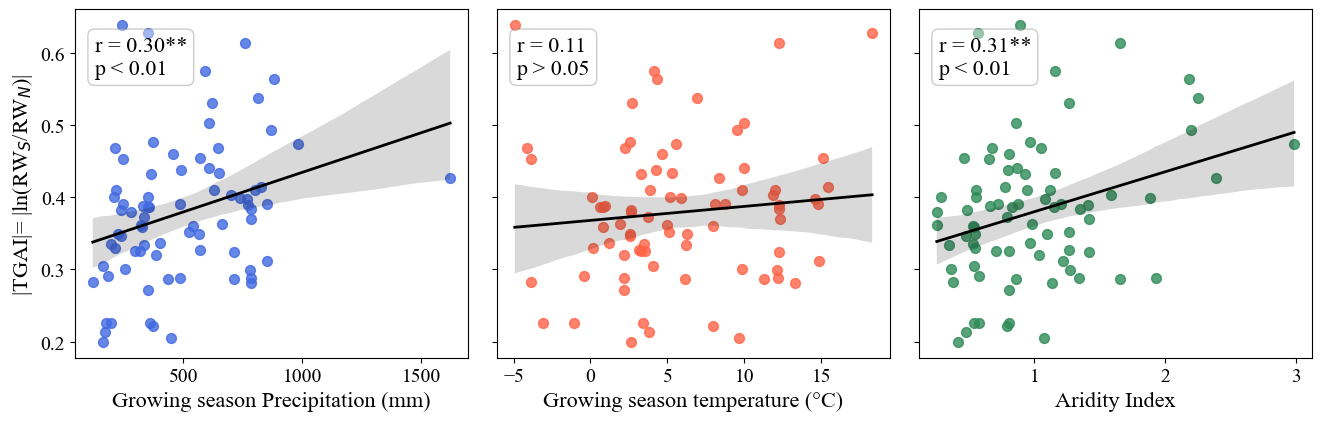

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import linregress
plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['font.size'] = 16
plt.rcParams["xtick.labelsize"] = 14
plt.rcParams["ytick.labelsize"] = 14
variables = [
    ('Pre_GS', 'Growing season Precipitation (mm)', 'royalblue'),
    # ('Pre_GS', 'Mean Annual Precipitation (mm)', 'royalblue'),
    ('Tmp_GS', 'Growing season temperature (°C)', 'tomato'),
    # ('Tmp_GS', 'Mean Annual temperature (°C)', 'tomato'),
    # ('ai_v3', 'Aridity Index', 'seagreen')
    ('ai_v3', 'Aridity Index', 'seagreen')
]
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.5), sharey=True)
for ax, (var, xlabel, color) in zip(axes, variables):
    x = df_meanC[var]
    y = df_meanC['Mean_abs_TGAI']
    slope, intercept, r_value, p_value, std_err = linregress(x, y)
    if p_value < 0.001:
        signif = '***'
        p_label = 'p < 0.001'
    elif p_value < 0.01:
        signif = '**'
        p_label = 'p < 0.01'
    elif p_value < 0.05:
        signif = '*'
        p_label = 'p < 0.05'
    else:
        signif = ''
        p_label = 'p > 0.05'
    r_text = f"r = {r_value:.2f}{signif}\n{p_label}"

    sns.regplot(
        x=x, y=y, ax=ax,
        scatter_kws={'alpha': 0.8, 'color': color, 's': 50},
        line_kws={'color': 'black', 'lw': 2},
        ci=95
    )
    ax.set_xlabel(xlabel)   
    if ax == axes[0]:
        ax.set_ylabel('|TGAI|= |ln(RW$_S$/RW$_N$)|')
    else:
        ax.set_ylabel('')
    ax.text(
        0.05, 0.80, r_text,
        transform=ax.transAxes,
        verticalalignment='bottom',
        bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray", alpha=0.4)
    )
plt.tight_layout()
plt.savefig(FIGURE_DIR / "Figure_1f_h_absolute_TGAI_climate.jpg", dpi=600, bbox_inches="tight")
plt.show()


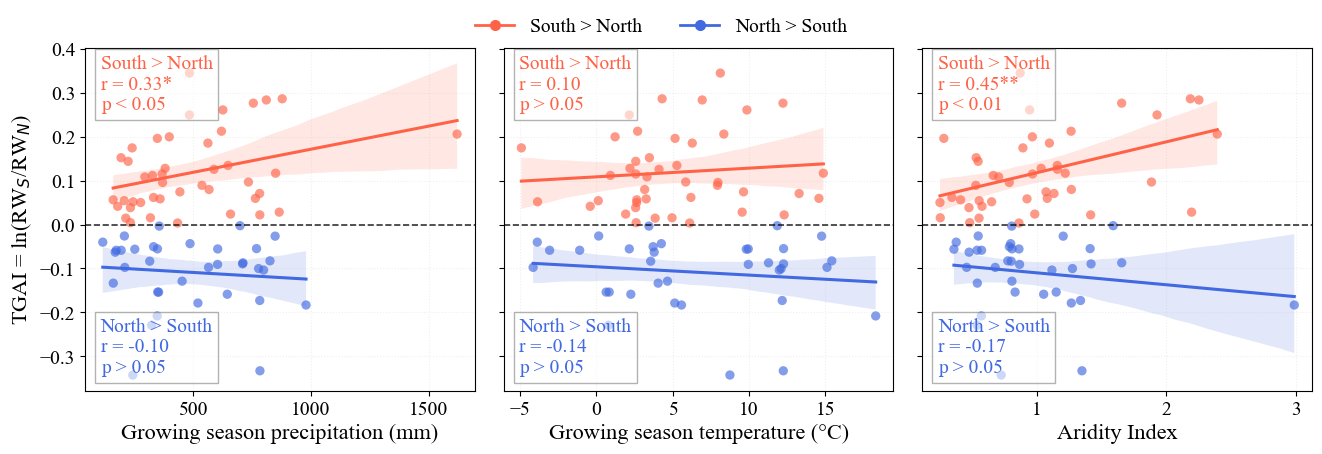

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy.stats import linregress
plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['font.size'] = 16
plt.rcParams["xtick.labelsize"] = 14
plt.rcParams["ytick.labelsize"] = 14
variables = [
    ('Pre_GS', 'Growing season precipitation (mm)'),
    ('Tmp_GS', 'Growing season temperature (°C)'),
    ('ai_v3', 'Aridity Index')
]
y_col = 'Mean'
color_south = 'tomato'
color_north = 'royalblue'
def get_p_label(p):
    if p < 0.001:
        return '***', 'p < 0.001'
    elif p < 0.01:
        return '**', 'p < 0.01'
    elif p < 0.05:
        return '*', 'p < 0.05'
    else:
        return '', 'p > 0.05'
fig, axes = plt.subplots(
    1, 3,
    figsize=(13.5, 4.5),
    sharey=True
)
for ax, (var, xlabel) in zip(axes, variables):
    temp = df_meanC[
        [var, y_col]
    ].dropna().copy()
    df_south = temp[
        temp[y_col] > 0
    ]
    df_north = temp[
        temp[y_col] < 0
    ]
    if len(df_south) >= 3:

        x_s = df_south[var]
        y_s = df_south[y_col]

        slope_s, intercept_s, r_s, p_s, std_s = linregress(
            x_s,
            y_s
        )
        star_s, p_label_s = get_p_label(p_s)
        sns.regplot(
            x=x_s,
            y=y_s,
            ax=ax,
            ci=95,

            scatter_kws={
                'alpha': 0.65,
                'color': color_south,
                's': 45,
                'edgecolor': 'none'
            },

            line_kws={
                'color': color_south,
                'lw': 2.2
            }
        )
    else:
        r_s = np.nan
        p_s = np.nan
        star_s = ''
        p_label_s = 'NA'
    if len(df_north) >= 3:

        x_n = df_north[var]
        y_n = df_north[y_col]

        slope_n, intercept_n, r_n, p_n, std_n = linregress(
            x_n,
            y_n
        )

        star_n, p_label_n = get_p_label(p_n)

        sns.regplot(
            x=x_n,
            y=y_n,
            ax=ax,
            ci=95,

            scatter_kws={
                'alpha': 0.65,
                'color': color_north,
                's': 45,
                'edgecolor': 'none'
            },

            line_kws={
                'color': color_north,
                'lw': 2.2
            }
        )

    else:
        r_n = np.nan
        p_n = np.nan
        star_n = ''
        p_label_n = 'NA'
    ax.axhline(
        0,
        color='black',
        linestyle='--',
        linewidth=1.2,
        alpha=0.8
    )
    ax.set_xlabel(xlabel)

    if ax == axes[0]:
        ax.set_ylabel(
            r'TGAI = ln(RW$_S$/RW$_N$)'
        )
    else:
        ax.set_ylabel('')
    text_s = (
        f"South > North\n"
        f"r = {r_s:.2f}{star_s}\n"
        f"{p_label_s}"
    )
    text_n = (
        f"North > South\n"
        f"r = {r_n:.2f}{star_n}\n"
        f"{p_label_n}"
    )
    ax.text(
        0.04,
        0.98,
        text_s,
        transform=ax.transAxes,
        ha='left',
        va='top',
        fontsize=14,
        color=color_south,
        bbox=dict(facecolor='white', edgecolor='gray', alpha=0.6)
    )
    ax.text(
        0.04,
        0.04,
        text_n,
        transform=ax.transAxes,
        ha='left',
        va='bottom',
        fontsize=14,
        color=color_north,
        bbox=dict(facecolor='white', edgecolor='gray', alpha=0.6)
    )
    ax.grid(
        alpha=0.20,
        linestyle=':'
    )

handles = [
    plt.Line2D(
        [0], [0],
        marker='o',
        linestyle='-',
        color=color_south,
        markersize=7,
        linewidth=2,
        label='South > North'
    ),

    plt.Line2D(
        [0], [0],
        marker='o',
        linestyle='-',
        color=color_north,
        markersize=7,
        linewidth=2,
        label='North > South'
    )
]
fig.legend(
    handles=handles,
    loc='upper center',
    bbox_to_anchor=(0.5, 1.04),
    ncol=2,
    frameon=False,
    fontsize=14
)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "Figure_1c_e_directional_TGAI_climate.jpg", dpi=600, bbox_inches="tight")
plt.show()

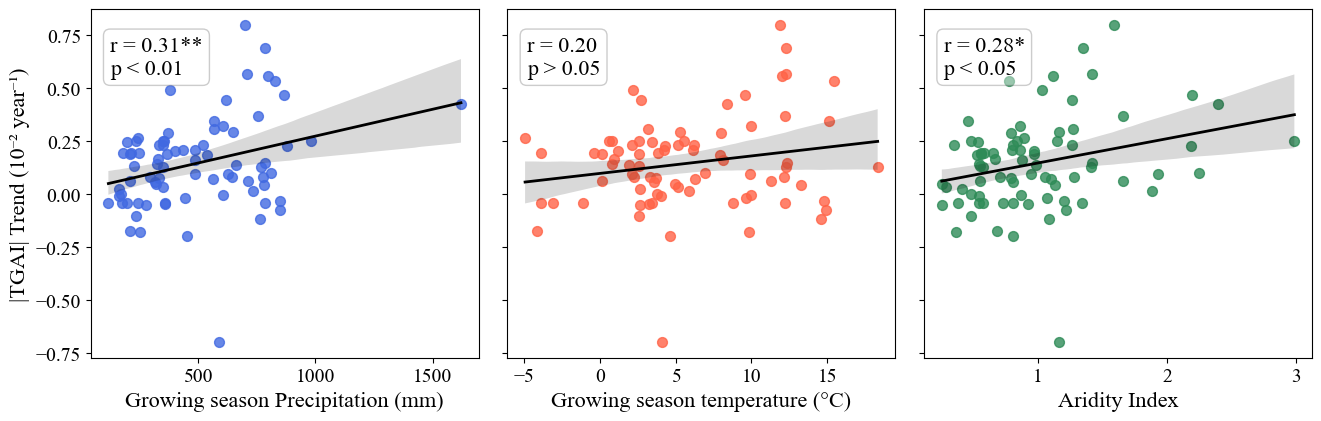

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import linregress

plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['font.size'] = 16
plt.rcParams["xtick.labelsize"] = 14
plt.rcParams["ytick.labelsize"] = 14
variables = [
    ('Pre_GS', 'Growing season Precipitation (mm)', 'royalblue'),
    # ('Pre_GS', 'Mean Annual Precipitation (mm)', 'royalblue'),
    ('Tmp_GS', 'Growing season temperature (°C)', 'tomato'),
    # ('Tmp_GS', 'Mean Annual temperature (°C)', 'tomato'),
    # ('ai_v3', 'Aridity Index', 'seagreen')
    ('ai_v3', 'Aridity Index', 'seagreen')
]
# y_limits = (0.7, 1.6)
y_ticks = [-1.0, -0.5, 0, 0.5, 1.0, 1.5]
y_label = "|TGAI| Trend (10⁻² year⁻¹)"
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.5), sharey=True)
for ax, (var, xlabel, color) in zip(axes, variables):
    x = df_meanC[var]
    y = df_meanC['Slope_Mean_abs_TGAI']* 100

    slope, intercept, r_value, p_value, std_err = linregress(x, y)

    if p_value < 0.001:
        signif = '***'
        p_label = 'p < 0.001'
    elif p_value < 0.01:
        signif = '**'
        p_label = 'p < 0.01'
    elif p_value < 0.05:
        signif = '*'
        p_label = 'p < 0.05'
    else:
        signif = ''
        p_label = 'p > 0.05'

    r_text = f"r = {r_value:.2f}{signif}\n{p_label}"

    sns.regplot(
        x=x, y=y, ax=ax,
        scatter_kws={'alpha': 0.8, 'color': color, 's': 50},
        line_kws={'color': 'black', 'lw': 2},
        ci=95
    )

    ax.set_xlabel(xlabel)

    
    if ax == axes[0]:
        ax.set_ylabel(y_label)
    else:
        ax.set_ylabel('')
    ax.text(
        0.05, 0.80, r_text,
        transform=ax.transAxes,
        verticalalignment='bottom',
        bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray", alpha=0.4)
    )
plt.tight_layout()
plt.savefig(FIGURE_DIR / "Figure_2c_e_TGAI_trend_climate.jpg", dpi=600, bbox_inches="tight")
plt.show()


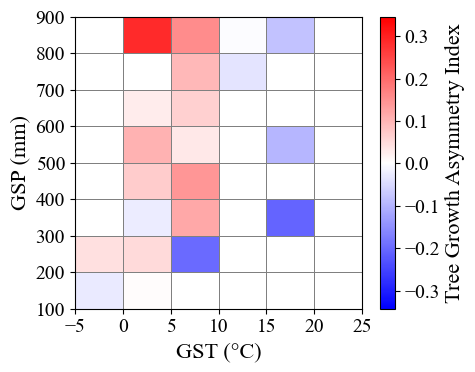

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['font.size'] = 16
plt.rcParams["xtick.labelsize"] = 14
plt.rcParams["ytick.labelsize"] = 14
temp_bins = np.arange(-5, 30, 5)  
prec_bins = np.arange(100, 1000, 100)  
df_meanC['temp_bin'] = pd.cut(df_meanC['Tmp_GS'], bins=temp_bins, include_lowest=True, right=False)
df_meanC['prec_bin'] = pd.cut(df_meanC['Pre_GS'], bins=prec_bins, include_lowest=True, right=False)
pivot_table = df_meanC.pivot_table(values='Mean', index='prec_bin', columns='temp_bin', aggfunc='mean')
temp_index = pd.IntervalIndex.from_breaks(temp_bins, closed='left')
prec_index = pd.IntervalIndex.from_breaks(prec_bins, closed='left')
pivot_table = pivot_table.reindex(index=prec_index, columns=temp_index)
z = pivot_table.to_numpy()
x_edges = temp_bins
y_edges = prec_bins
assert z.shape == (len(y_edges) - 1, len(x_edges) - 1)
fig, ax = plt.subplots(figsize=(5, 4))
norm = mcolors.TwoSlopeNorm(vmin=df_meanC['Mean'].min(), vcenter=0, vmax=df_meanC['Mean'].max())
cmap = plt.get_cmap('bwr')
mesh = ax.pcolormesh(x_edges, y_edges, z,
                     cmap=cmap, norm=norm,
                     edgecolors='gray', linewidth=0.5)
ax.set_xticks(temp_bins)
ax.set_yticks(prec_bins)
ax.set_xlabel("GST (°C)", fontsize=16)
ax.set_ylabel("GSP (mm)", fontsize=16)
ax.tick_params(labelsize=14)
cbar = plt.colorbar(mesh, ax=ax)
cbar.set_label("Tree Growth Asymmetry Index", fontsize=16)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "Figure_1b_climate_space.jpg", dpi=600, bbox_inches="tight")
plt.show()

## 11. Species-level patterns (Figure S6)


In [20]:
species_summary = (
    dfslope_4_N_P_mean
    .groupby("Tree_Speci")
    .agg(
        n_sites=("Mean", "count"),
        Mean_TGAI=("Mean", "mean"),
        Median_TGAI=("Mean", "median"),
        Mean_Slope=("Slope_Mean", "mean"),
        Median_Slope=("Slope_Mean", "median")
    )
    .reset_index()
)
MIN_N = 1
species_summary = species_summary[species_summary["n_sites"] >= MIN_N]

In [21]:
import seaborn as sns
import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['font.size'] = 16
plt.rcParams["xtick.labelsize"] = 14
plt.rcParams["ytick.labelsize"] = 14

df_plot = dfslope_4_N_P_mean[
    dfslope_4_N_P_mean["Tree_Speci"].isin(species_summary["Tree_Speci"])
].copy()

order = (df_plot.groupby("Tree_Speci")["Mean"]
         .median()
         .sort_values(ascending=False)
         .index)

colors = sns.color_palette("tab20", n_colors=len(order))
palette = dict(zip(order, colors))


C:\Users\MSI\AppData\Local\Temp\ipykernel_34836\2316841405.py:36: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\MSI\AppData\Local\Temp\ipykernel_34836\2316841405.py:57: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


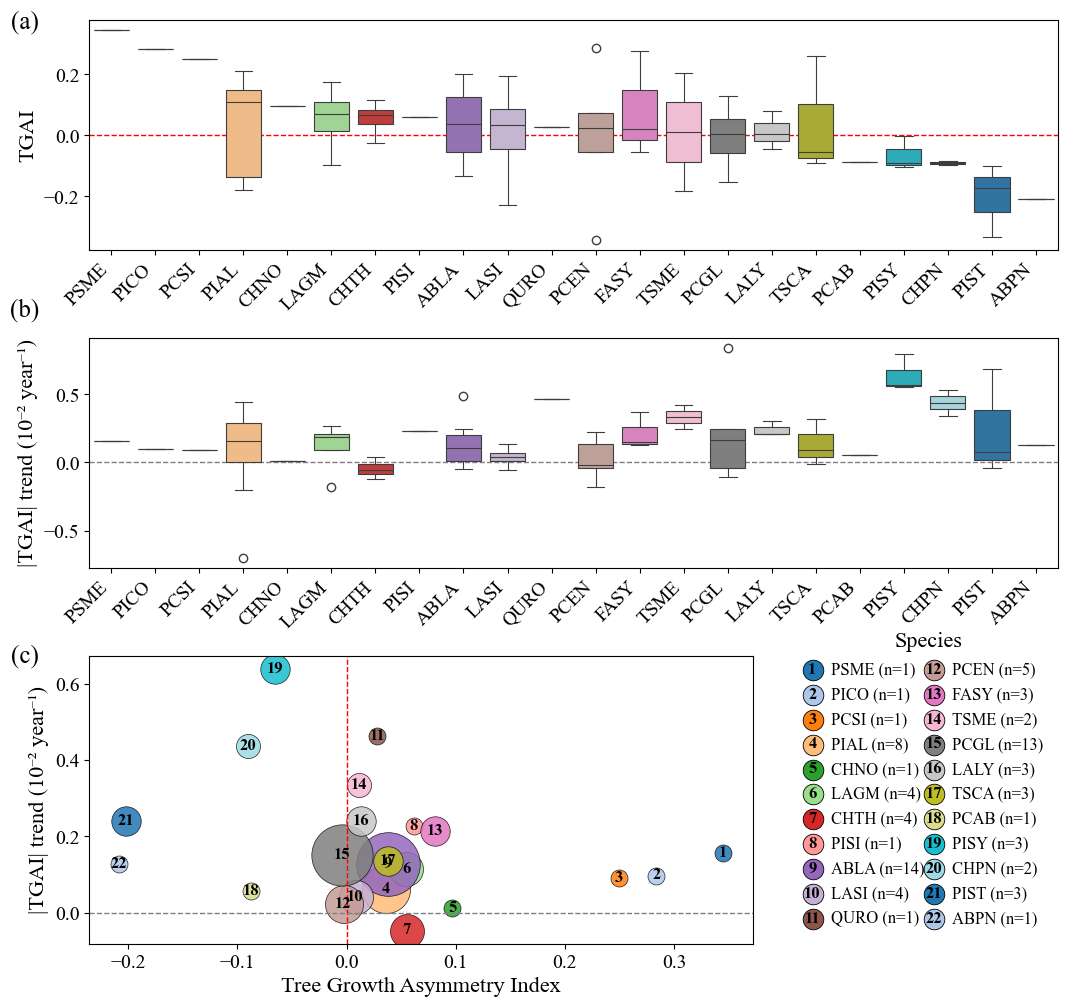

In [22]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
df_plot2 = df_plot.copy()
df_plot2["Slope_Mean_x100"] = df_plot2["Slope_Mean_abs_TGAI"] * 100
ss = (
    df_plot2.groupby("Tree_Speci", as_index=False)
    .agg(
        n_sites=("Mean", "count"),
        Mean_TGAI=("Mean", "mean"),
        Mean_Slope_x100=("Slope_Mean_x100", "mean")
    )
)

ss["Tree_Speci"] = pd.Categorical(ss["Tree_Speci"], categories=list(order), ordered=True)
ss = ss.sort_values("Tree_Speci").reset_index(drop=True)
ss["sp_id"] = np.arange(1, len(ss) + 1)
def sig2(x, pos):
    if x == 0 or np.isclose(x, 0):
        return "0"
    return f"{x:.2g}"
fig = plt.figure(figsize=(12.5, 12.0))
gs = fig.add_gridspec(
    3, 2,
    height_ratios=[1.0, 1.0, 1.25],
    width_ratios=[0.72, 0.28],
    hspace=0.35, wspace=0.10
)

ax1 = fig.add_subplot(gs[0, :])
ax2 = fig.add_subplot(gs[1, :])
ax3 = fig.add_subplot(gs[2, 0])
axL = fig.add_subplot(gs[2, 1])
sns.boxplot(
    data=df_plot,
    x="Tree_Speci", y="Mean",
    order=order,
    palette=palette,
    showfliers=True,
    linewidth=0.8,
    ax=ax1
)
ax1.axhline(0, ls="--", color="red", lw=1)
ax1.set_ylabel("TGAI")
# ax1.yaxis.set_ticks([0.8, 1.0, 1.2, 1.4, 1.6])
ax1.text(-3.0, 3.2, "(a)", transform=axL.transAxes, ha="center", va="center", fontsize=18)
ax1.set_xlabel("")
ax1.tick_params(axis="x", labelrotation=45)
for lbl in ax1.get_xticklabels():
    lbl.set_horizontalalignment("right")
# ax1.yaxis.set_major_formatter(yfmt)

ax1.set_title("")

sns.boxplot(
    data=df_plot2,
    x="Tree_Speci", y="Slope_Mean_x100",
    order=order,
    palette=palette,
    showfliers=True,
    linewidth=0.8,
    ax=ax2
)
ax2.axhline(0, ls="--", color="gray", lw=1)
ax2.set_ylabel("|TGAI| trend (10⁻² year⁻¹)")
ax2.set_xlabel("")
ax2.tick_params(axis="x", labelrotation=45)
ax2.text(-3.0, 2.2, "(b)", transform=axL.transAxes, ha="center", va="center",fontsize=18)
for lbl in ax2.get_xticklabels():
    lbl.set_horizontalalignment("right")
for _, r in ss.iterrows():
    sp = r["Tree_Speci"]
    if pd.isna(sp):
        continue

    ax3.scatter(
        r["Mean_TGAI"], r["Mean_Slope_x100"],
        s=max(int(r["n_sites"]), 1) * 150,
        color=palette[sp],
        alpha=0.85,
        edgecolor="black",
        linewidth=0.5,
        zorder=2
    )
    ax3.text(
        r["Mean_TGAI"], r["Mean_Slope_x100"],
        str(int(r["sp_id"])),
        ha="center", va="center",
        fontsize=12, fontweight="bold",
        zorder=3
    )

ax3.axvline(0, color="red", ls="--", lw=1)
ax3.axhline(0, color="gray", ls="--", lw=1)
ax3.set_xlabel("Tree Growth Asymmetry Index")
ax3.set_ylabel("|TGAI| trend (10⁻² year⁻¹)")
# ax3.yaxis.set_major_formatter(yfmt)
ax3.text(-3.0, 1.0, "(c)", transform=axL.transAxes, ha="center", va="center",fontsize=18)
axL.axis("off")
# axL.set_title("Species") 

items = []
for _, r in ss.iterrows():
    sp = r["Tree_Speci"]
    if pd.isna(sp):
        continue
    items.append((int(r["sp_id"]), sp, int(r["n_sites"]), palette[sp]))

ncol = 2
n = len(items)
nrow = int(np.ceil(n / ncol))

x_cols = [0.05, 0.52]
y0 = 0.95
dy = 0.95 / max(nrow, 1)
circle_size = 220
fs_id = 12
fs_text = 12

for i, (sid, sp, nn, col) in enumerate(items):
    c = i // nrow
    rr = i % nrow
    x = x_cols[c]
    y = y0 - rr * dy

    axL.scatter(
        x, y,
        s=circle_size,
        color=col,
        edgecolor="black",
        linewidth=0.6,
        transform=axL.transAxes,
        zorder=2
    )
    axL.text(
        x, y, str(sid),
        transform=axL.transAxes,
        ha="center", va="center",
        fontsize=fs_id,
        fontweight="bold",
        color="black",
        zorder=3
    )
    axL.text(
        x + 0.07, y,
        f"{sp} (n={nn})",
        transform=axL.transAxes,
        ha="left", va="center",
        fontsize=fs_text
    )
axL.text(0.5, 1.05, "Species", transform=axL.transAxes, ha="center", va="center")
plt.savefig(FIGURE_DIR / "Figure_S6_species_patterns.jpg", dpi=600, bbox_inches="tight")
plt.show()


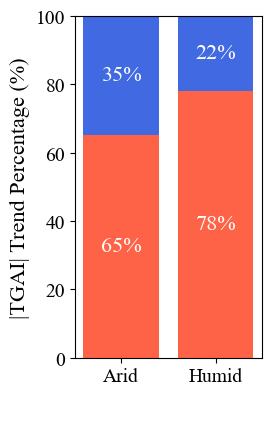

In [23]:
df_meanC['climate_zone'] = np.where(df_meanC['ai_v3'] < ARIDITY_THRESHOLD, 'Arid', 'Humid')
def calc_positive_slope_ratio(group):
    total = len(group)
    positive = (group['Slope_Mean_abs_TGAI'] > 0).sum()
    return round(positive / total, 3) if total > 0 else np.nan

slope_ratio = df_meanC.groupby('climate_zone').apply(calc_positive_slope_ratio).rename('Positive_Slope_Ratio')

plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['font.size'] = 16
df_meanC['Trend'] = df_meanC['Slope_Mean_abs_TGAI'].apply(lambda x: 'Increasing' if x > 0 else 'Decreasing')
df_percent = (
    df_meanC.groupby(['climate_zone', 'Trend'])
       .size()
       .reset_index(name='Count')
       .pivot(index='climate_zone', columns='Trend', values='Count')
       .fillna(0)
)
df_percent['Total'] = df_percent.sum(axis=1)
df_percent['Increasing_%'] = df_percent['Increasing'] / df_percent['Total'] * 100
df_percent['Decreasing_%'] = df_percent['Decreasing'] / df_percent['Total'] * 100
fig, ax = plt.subplots(figsize=(3, 4.5))
climate_zones = df_percent.index.tolist()
increasing = df_percent['Increasing_%'].values
decreasing = df_percent['Decreasing_%'].values
ax.bar(climate_zones, increasing, label='Increasing', color='tomato')
ax.bar(climate_zones, decreasing, bottom=increasing, label='Decreasing', color='royalblue')
ax.set_ylabel('|TGAI| Trend Percentage (%)', fontsize=16)
ax.set_xlabel(' ')
ax.set_ylim(0, 100)

for i, (inc, dec) in enumerate(zip(increasing, decreasing)):
    ax.text(i, inc / 2, f'{inc:.0f}%', ha='center', va='center', color='white', fontsize=16)
    ax.text(i, inc + dec / 2, f'{dec:.0f}%', ha='center', va='center', color='white', fontsize=16)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "Figure_2b_climate_region_trends.jpg", dpi=600, bbox_inches="tight")
plt.show()


## 12. Build annual TGAI data set


In [24]:
dfslope_4_N_P_mean = dfslope_4_N_P_mean.rename(
    columns={"ai_v3": "AI", "Site_ID": "site"}
)
folder = TREE_RING_DIR
dfslope_4_N_P_mean = dfslope_4_N_P_mean.copy()

dfslope_4_N_P_mean['site'] = (dfslope_4_N_P_mean['site'].astype(str).str.strip().str.upper())
target_sites = ( dfslope_4_N_P_mean['site'].dropna().unique())
prefix_filter = set(sig_df['Prefix'].dropna().astype(str).str.strip().str.upper().unique())
records = []
for site in target_sites:
    filename = site + ".rwl.csv"
    filepath = os.path.join(folder, filename)
    if not os.path.exists(filepath):
        print(f"File not found: {filename}")
        continue

    try:
        df = pd.read_csv(
            filepath,
            index_col=0
        )
        df.index = pd.to_numeric(
            df.index,
            errors="coerce"
        )
        df = df[
            df.index.notna()
        ].copy()
        df.index = df.index.astype(int)
        df.columns = [
            str(col).strip().upper()
            for col in df.columns
        ]
        df = df[
            (df.index >= START_YEAR) &
            (df.index <= END_YEAR)
        ].copy()
    except Exception as e:
        print(
            f"Error processing {filename}: {e}"
        )
        continue
    all_cols = df.columns.tolist()
    for col_n in all_cols:
        if not col_n.endswith("N"):
            continue
        prefix = col_n[:-1]
        if prefix not in prefix_filter:
            continue

        col_s = prefix + "S"

        if col_s not in all_cols:
            continue
        n_vals = pd.to_numeric(
            df[col_n],
            errors="coerce"
        )

        s_vals = pd.to_numeric(
            df[col_s],
            errors="coerce"
        )
        pair_df = pd.DataFrame({
            "N": n_vals,
            "S": s_vals
        })
        pair_df = pair_df.dropna()
        pair_df = pair_df[
            (pair_df["N"] > 0) &
            (pair_df["S"] > 0)
        ].copy()
        if len(pair_df) == 0:
            continue
        pair_df["TGAI"] = np.log(pair_df["S"] /pair_df["N"]
        )
        pair_df["Abs_TGAI"] = np.abs(
            pair_df["TGAI"]
        )
        df_tgai = pd.DataFrame({
            "Year":
                pair_df.index,
            "Prefix":
                prefix,
            "site":
                site,
            "RW_N":
                pair_df["N"].values,
            "RW_S":
                pair_df["S"].values,
            "TGAI":
                pair_df["TGAI"].values,
            "Abs_TGAI":
                pair_df["Abs_TGAI"].values
        })
        records.append(df_tgai)
if records:
    df_all_tgai = pd.concat(
        records,
        ignore_index=True
    )
else:
    raise ValueError(
        "No valid TGAI records were generated."
    )
lower_bound = (df_all_tgai["TGAI"].quantile(0.01))
upper_bound = (df_all_tgai["TGAI"].quantile(0.99))
df_filtered = df_all_tgai[df_all_tgai["TGAI"].between(lower_bound,upper_bound,inclusive="both")].copy()
df_filtered["site"] = ( df_filtered["site"].astype(str).str.strip().str.upper())
df_filtered = df_filtered.merge(
    dfslope_4_N_P_mean[
        [
            "site",
            "AI"
        ]
    ].drop_duplicates(
        subset="site"
    ),
    on="site",
    how="left"
)
df_filtered["climate_zone"] = np.where(df_filtered["AI"] < ARIDITY_THRESHOLD,"arid","humid")
df_filtered.loc[df_filtered["AI"].isna(),"climate_zone"] = np.nan


In [25]:
df_site_tree = (df_filtered.groupby('site')['Prefix'].nunique()
    .reset_index(name='Prefix_count')
)
total = df_site_tree['Prefix_count'].sum()
print(total)


738


In [26]:
df_site_tree.to_csv(TABLE_DIR / "site_tree_counts.csv", index=False)

## 13. Hemispheric temporal patterns (Figure 3a-b)


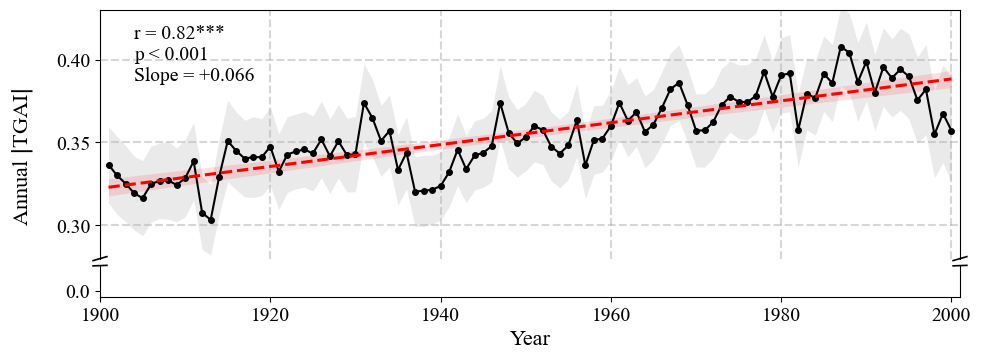

In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import linregress
import statsmodels.api as sm
plt.style.use('default')
plt.rcParams.update({
    'font.family': 'Times New Roman',
    'font.size': 16,
    'xtick.labelsize': 14,
    'ytick.labelsize': 14
})
df_filtered_2000 = df_filtered[df_filtered['Year'] <= 2000].copy()
annual = (df_filtered_2000.groupby('Year')['Abs_TGAI'].agg(['mean', 'std', 'count']).reset_index())
annual.columns = ['Year', 'Abs_TGAI', 'SD', 'n']
annual['SE'] = annual['SD'] / np.sqrt(annual['n'])
annual['CI95'] = 1.96 * annual['SE']
x = annual['Year'].to_numpy(float)
y = annual['Abs_TGAI'].to_numpy(float)
res = linregress(x, y)
slope = res.slope
r_value = res.rvalue
p_value = res.pvalue
X = sm.add_constant(x)
model = sm.OLS(y, X).fit()
pred = model.get_prediction(X)
mean_pred = pred.predicted_mean
trend_ci = pred.conf_int(alpha=0.05)
if p_value < 0.001:
    sig, p_label = '***', 'p < 0.001'
elif p_value < 0.01:
    sig, p_label = '**', 'p < 0.01'
elif p_value < 0.05:
    sig, p_label = '*', 'p < 0.05'
else:
    sig, p_label = '', 'p ≥ 0.05'

textstr = (
    f'r = {r_value:.2f}{sig}\n'
    f'{p_label}\n'
    f'Slope = {slope * 100:+.3f}'
)
fig, (ax, ax0) = plt.subplots(2, 1,sharex=True,figsize=(10, 3.5),gridspec_kw={'height_ratios': [8, 1],'hspace': 0.05})
ax.fill_between(x,y - annual['CI95'].to_numpy(),
                y + annual['CI95'].to_numpy(),color='gray',alpha=0.16,linewidth=0)
ax.plot(
    x, y,color='black',
    marker='o',markersize=4,linewidth=1.5,zorder=4)
ax.fill_between(
    x,trend_ci[:, 0],
    trend_ci[:, 1],color='red',alpha=0.12,linewidth=0)
ax.plot(x,mean_pred,color='red',linestyle='--',linewidth=2.2,zorder=5)
ax.text(
    0.04, 0.94,
    textstr,
    transform=ax.transAxes,
    ha='left',
    va='top',
    fontsize=14
)
ax.set_ylim(0.28, 0.43)
ax.set_yticks([0.30,0.35, 0.4])
ax0.set_ylim(-0.005, 0.02)
ax0.set_yticks([0])
ax0.set_yticklabels(['0.0'])
ax.spines['bottom'].set_visible(False)
ax0.spines['top'].set_visible(False)
ax.tick_params(bottom=False,labelbottom=False)
d = 0.008
kwargs = dict(transform=ax.transAxes,color='black',clip_on=False,linewidth=1.2)
ax.plot((-d, +d),(-d, +d),**kwargs)
ax.plot( (1-d, 1+d),(-d, +d),**kwargs)
kwargs.update(transform=ax0.transAxes)
ax0.plot((-d, +d),(1-d, 1+d),**kwargs)
ax0.plot((1-d, 1+d),(1-d, 1+d),**kwargs)
ax0.set_xlim(1900, 2001)
ax0.set_xticks( np.arange(1900, 2001, 20))
ax0.set_xlabel('Year',fontsize=16)
fig.text(0.02,0.55,r'Annual $|$TGAI$|$',rotation=90,va='center',fontsize=16)
ax.grid(True,linestyle='--',linewidth=1.5,alpha=0.50)
plt.subplots_adjust(left=0.11,right=0.97,bottom=0.15,top=0.97)
plt.savefig(FIGURE_DIR / "Figure_3a_annual_absolute_TGAI.jpg", dpi=600, bbox_inches="tight")
plt.show()



=== ANCOVA result ===
                    sum_sq       df             F        PR(>F)
C(Group)       3898.492217      1.0  27353.686662  0.000000e+00
Year              5.601452      1.0     39.302467  3.654104e-10
Year:C(Group)    28.920339      1.0    202.918936  5.714083e-46
Residual       8667.595912  60816.0           NaN           NaN
TGAI < 0: r = -0.412, slope = -0.0415, p = 2.023e-05
TGAI > 0: r = 0.844, slope = +0.1104, p = 2.8e-28


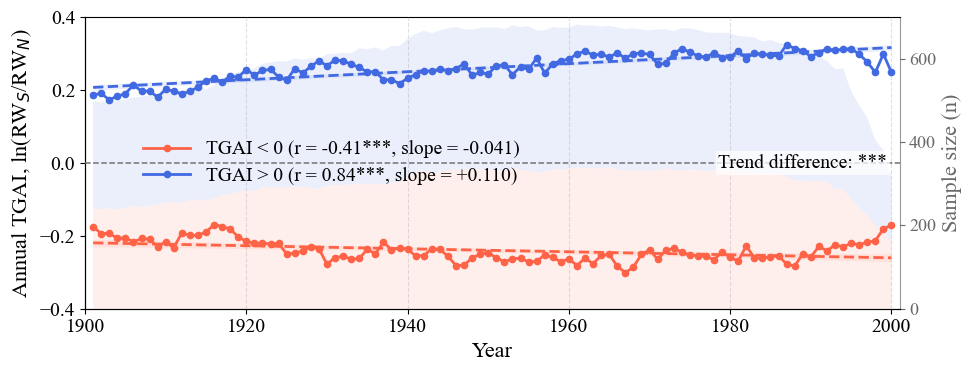


=== ANCOVA summary interpretation ===
Year main effect: *** (p = 3.654e-10)
Group main effect: *** (p = 0)
Year × Group interaction: *** (p = 5.714e-46)
Temporal slopes differ significantly between the two groups.


In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import linregress, t
import statsmodels.formula.api as smf
import statsmodels.api as sm
plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['font.size'] = 16
plt.rcParams['xtick.labelsize'] = 14
plt.rcParams['ytick.labelsize'] = 14
def p_symbol(p):
    if pd.isna(p):
        return "NA"
    elif p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < 0.05:
        return "*"
    else:
        return "ns"
df = df_filtered_2000[['Year', 'site', 'Prefix', 'TGAI']].dropna().copy()
df['Year'] = df['Year'].astype(int)
tree_mean = (
    df.groupby(['site', 'Prefix'])['TGAI']
      .mean()
      .rename('Mean_TGAI')
      .reset_index()
)
tree_mean['Group'] = np.where(
    tree_mean['Mean_TGAI'] > 0, 'TGAI > 0',
    np.where(tree_mean['Mean_TGAI'] < 0, 'TGAI < 0', 'TGAI = 0')
)
df = df.merge(tree_mean, on=['site', 'Prefix'], how='left')
df = df[df['Group'] != 'TGAI = 0'].copy()
groups = ['TGAI < 0', 'TGAI > 0']
colors = {'TGAI < 0': 'tomato', 'TGAI > 0': 'royalblue'}
annual = (
    df.groupby(['Year', 'Group'], observed=True)
      .agg(TGAI=('TGAI', 'mean'), n=('TGAI', 'size'))
      .reset_index()
)
n_wide = (
    annual.pivot(index='Year', columns='Group', values='n')
          .reindex(columns=groups)
          .fillna(0)
          .sort_index()
)

years = n_wide.index.to_numpy(float)
n_neg = n_wide['TGAI < 0'].to_numpy(float)
n_pos = n_wide['TGAI > 0'].to_numpy(float)
model = smf.ols('TGAI ~ Year * C(Group)', data=df).fit()
anova = sm.stats.anova_lm(model, typ=2)
print("\n=== ANCOVA result ===")
print(anova)
p_year = anova.loc['Year', 'PR(>F)'] if 'Year' in anova.index else np.nan
p_group = anova.loc['C(Group)', 'PR(>F)'] if 'C(Group)' in anova.index else np.nan
p_inter = anova.loc['Year:C(Group)', 'PR(>F)'] if 'Year:C(Group)' in anova.index else np.nan
fig, ax1 = plt.subplots(figsize=(10, 4))
ax2 = ax1.twinx()
ax1.set_zorder(2)
ax2.set_zorder(1)
ax1.patch.set_alpha(0)
ax2.stackplot(
    years,
    n_neg,
    n_pos,
    colors=[colors['TGAI < 0'], colors['TGAI > 0']],
    alpha=0.10,
    zorder=0
)
line_handles = []
for g in groups:
    d = annual[annual['Group'] == g].sort_values('Year').copy()
    if d.empty:
        continue
    x = d['Year'].to_numpy(float)
    y = d['TGAI'].to_numpy(float)

    line, = ax1.plot(
        x, y, 'o-',
        color=colors[g],
        lw=2.0,
        ms=4.5,
        zorder=5
    )

    res = linregress(x, y)
    slope = res.slope
    intercept = res.intercept
    r = res.rvalue
    p = res.pvalue
    yfit = intercept + slope * x
    ax1.plot(
        x, yfit, '--',
        color=colors[g],
        lw=2.0,
        zorder=6
    )

    n = len(x)
    sxx = np.sum((x - x.mean()) ** 2)

    if n >= 3 and sxx > 0:
        serr = np.sqrt(np.sum((y - yfit) ** 2) / (n - 2))
        ci = t.ppf(0.975, n - 2) * serr * np.sqrt(1 / n + (x - x.mean()) ** 2 / sxx)

        ax1.fill_between(
            x, yfit - ci, yfit + ci,
            color=colors[g],
            alpha=0.10,
            linewidth=0,
            zorder=2
        )
    slope100 = slope * 100
    label = f"{g} (r = {r:.2f}{p_symbol(p)}, slope = {slope100:+.3f})"
    line.set_label(label)
    line_handles.append(line)
    print(f"{g}: r = {r:.3f}, slope = {slope100:+.4f}, p = {p:.4g}")

ax1.axhline(0, color='0.45', linestyle='--', linewidth=1.1, zorder=3)
ax1.set_yticks([-0.4, -0.2, 0.0, 0.2, 0.4])
ax1.set_xlim(1900, 2001)
ax1.set_xticks(np.arange(1900, 2001, 20))
ymax = max(abs(annual['TGAI'].min()), abs(annual['TGAI'].max()))
# ax1.set_ylim(-ymax * 1.18, ymax * 1.18)
ax1.set_xlabel("Year", fontsize=16)
ax1.set_ylabel(r"Annual TGAI, ln(RW$_S$/RW$_N$)", fontsize=16)
ax1.grid(axis='x', linestyle='--', alpha=0.4)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax2.set_ylim(0, 700)
ax2.set_yticks([0, 200, 400, 600])
ax2.set_ylabel("Sample size (n)", fontsize=16, color='dimgray')
ax2.tick_params(axis='y', labelsize=13, colors='dimgray')
ax2.yaxis.label.set_color('dimgray')
ax2.spines['right'].set_alpha(0.4)
# ax2.spines['top'].set_visible(False)
ax1.legend(
    handles=line_handles,
    loc='center left',
    bbox_to_anchor=(0.05, 0.50),
    frameon=False,
    fontsize=14,
    handlelength=2.4,
    labelspacing=0.45
)
ax1.text(
    0.985, 0.50,
    f"Trend difference: {p_symbol(p_inter)}",
    transform=ax1.transAxes,
    ha='right',
    va='center',
    fontsize=14,
    bbox=dict(facecolor='white', edgecolor='none', alpha=0.75, pad=2)
)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "Figure_3b_directional_TGAI_trends.jpg", dpi=600, bbox_inches="tight")
plt.show()
print("\n=== ANCOVA summary interpretation ===")
print(f"Year main effect: {p_symbol(p_year)} (p = {p_year:.4g})" if pd.notna(p_year) else "Year main effect: NA")
print(f"Group main effect: {p_symbol(p_group)} (p = {p_group:.4g})" if pd.notna(p_group) else "Group main effect: NA")
print(f"Year × Group interaction: {p_symbol(p_inter)} (p = {p_inter:.4g})" if pd.notna(p_inter) else "Year × Group interaction: NA")

if pd.notna(p_inter):
    if p_inter < 0.05:
        print("Temporal slopes differ significantly between the two groups.")
    else:
        print("Temporal slopes do not differ significantly between the two groups.")


## 14. Temporal sample distribution (Figure S1)


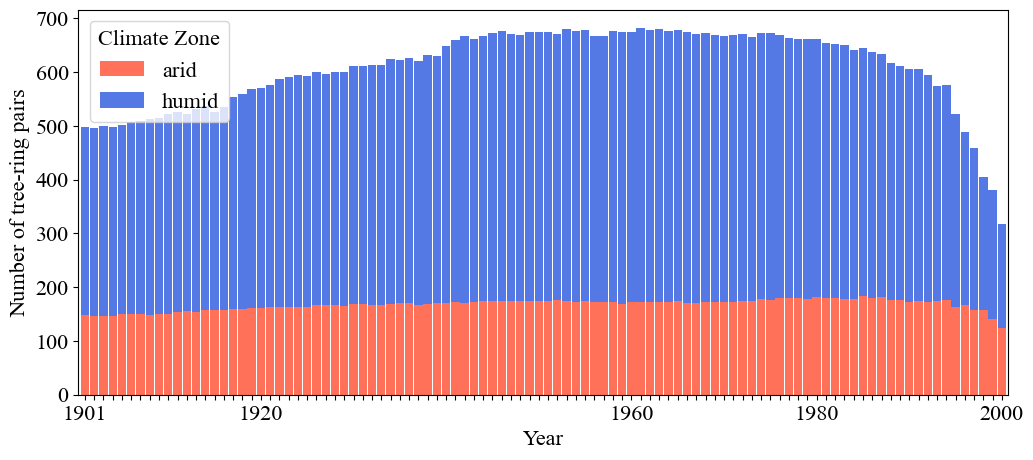

In [29]:
import pandas as pd
import matplotlib.pyplot as plt
plt.style.use('default')
plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['font.size'] = 16
plt.rcParams["xtick.labelsize"] = 16
plt.rcParams["ytick.labelsize"] = 16
pivot_df = df_filtered.groupby(['Year', 'climate_zone']).size().unstack(fill_value=0)
pivot_df = pivot_df.sort_index()
custom_colors = ['tomato','royalblue']  
xtick_years = [1901, 1920, 1960, 1980, 2000]
ax = pivot_df.plot(
    kind='bar',
    stacked=True,
    width = 0.9,
    alpha=0.9,
    figsize=(12, 5),
    color=custom_colors[:len(pivot_df.columns)]  
)
ax.set_xlabel('Year')
ax.set_ylabel('Number of tree-ring pairs')
ax.set_xticks(range(len(pivot_df.index)))
new_labels = [str(year) if year in xtick_years else '' for year in pivot_df.index]
ax.set_xticklabels(new_labels, rotation=0)
plt.legend(title='Climate Zone')
# plt.tight_layout()
plt.savefig(FIGURE_DIR / "Figure_S1_temporal_sample_size.jpg", dpi=600, bbox_inches="tight")
plt.show()


## 15. Alternative climate window sensitivity


In [32]:
import numpy as np
if not hasattr(np, "alen"):
    np.alen = lambda a: len(a)
import geopandas as gpd
import xarray as xr
import pandas as pd
import numpy as np
pre_path = CRU_PRE
tmp_path = CRU_TMP
gdf = gdf.copy()
if 'Longitude' not in gdf.columns or 'Latitude' not in gdf.columns:
    gdf['Longitude'] = gdf.geometry.x
    gdf['Latitude'] = gdf.geometry.y
ds_pre = xr.open_dataset(pre_path)
ds_tmp = xr.open_dataset(tmp_path)
gs_months = np.arange(1, 13)
pre = ds_pre['pre']  
pre_gs = pre.where(pre['time'].dt.month.isin(gs_months), drop=True)
pre_gs_annual = pre_gs.groupby('time.year').sum(dim='time')
pre_gs_clim = pre_gs_annual.mean(dim='year')
tmp = ds_tmp['tmp']  # °C
tmp_gs = tmp.where(tmp['time'].dt.month.isin(gs_months), drop=True)
tmp_gs_annual = tmp_gs.groupby('time.year').mean(dim='time')
tmp_gs_clim = tmp_gs_annual.mean(dim='year')
lon_points = xr.DataArray(gdf['Longitude'].values, dims=('points',))
lat_points = xr.DataArray(gdf['Latitude'].values, dims=('points',))
pre_gs_vals = pre_gs_clim.interp(lon=lon_points, lat=lat_points, method='linear').values
tmp_gs_vals = tmp_gs_clim.interp(lon=lon_points, lat=lat_points, method='linear').values
gdf['Pre_GS'] = pre_gs_vals
gdf['Tmp_GS'] = tmp_gs_vals
print(gdf[['Longitude', 'Latitude', 'Pre_GS', 'Tmp_GS']].head())
df_meanC = gdf.dropna(subset=['Pre_GS', 'Tmp_GS', 'Mean']).copy()

    Longitude   Latitude       Pre_GS     Tmp_GS
0  108.654847  33.440325   890.394774  10.719915
1  108.905503  35.554255   606.973100   9.652907
2   -5.415830  36.768000   750.260252  15.543492
3  -74.420000  41.115000  1214.832812   9.875924
4  -74.326000  41.206000  1213.714102   9.746905


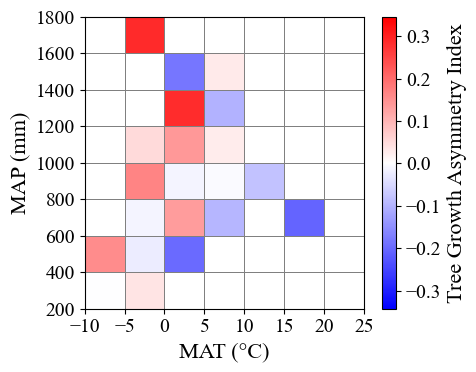

In [35]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['font.size'] = 16
plt.rcParams["xtick.labelsize"] = 14
plt.rcParams["ytick.labelsize"] = 14
temp_bins = np.arange(-10, 30, 5)       
prec_bins = np.arange(200, 2000, 200)  
df_meanC['temp_bin'] = pd.cut(df_meanC['Tmp_GS'], bins=temp_bins, include_lowest=True, right=False)
df_meanC['prec_bin'] = pd.cut(df_meanC['Pre_GS'], bins=prec_bins, include_lowest=True, right=False)
pivot_table = df_meanC.pivot_table(values='Mean', index='prec_bin', columns='temp_bin', aggfunc='mean')
temp_index = pd.IntervalIndex.from_breaks(temp_bins, closed='left')
prec_index = pd.IntervalIndex.from_breaks(prec_bins, closed='left')
pivot_table = pivot_table.reindex(index=prec_index, columns=temp_index)
z = pivot_table.to_numpy()
x_edges = temp_bins
y_edges = prec_bins
assert z.shape == (len(y_edges) - 1, len(x_edges) - 1)
fig, ax = plt.subplots(figsize=(5, 4))
norm = mcolors.TwoSlopeNorm(vmin=df_meanC['Mean'].min(), vcenter=0, vmax=df_meanC['Mean'].max())
cmap = plt.get_cmap('bwr')
mesh = ax.pcolormesh(x_edges, y_edges, z,
                     cmap=cmap, norm=norm,
                     edgecolors='gray', linewidth=0.5)
ax.set_xticks(temp_bins)
ax.set_yticks(prec_bins)

ax.set_xlabel("MAT (°C)", fontsize=16)
ax.set_ylabel("MAP (mm)", fontsize=16)
ax.tick_params(labelsize=14)
cbar = plt.colorbar(mesh, ax=ax)
cbar.set_label("Tree Growth Asymmetry Index", fontsize=16)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "Figure_climate_window_sensitivity.jpg", dpi=600, bbox_inches="tight")
plt.show()
